# Klasifikasi Tingkat Kantuk Mahasiswa dengan Seleksi Fitur PCA
Proyek Penambangan Data INF11121. Jalankan sel 1 sampai 15 (termasuk Sel 4b) **berurutan** (Runtime > Run all juga boleh; sel 10, 11, 12 butuh beberapa menit).
Label: Mengantuk (jawaban kantuk Kadang-kadang ke atas) dan Tidak Mengantuk (Tidak pernah, Jarang).

## Sel 1. Persiapan dan unggah file

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, io, os, re
from scipy import stats
from IPython.display import display
SEED = 42
np.random.seed(SEED)
os.makedirs("hasil", exist_ok=True)
try:
    from google.colab import files
    up = files.upload()                      # pilih file CSV kuesioner
    NAMA_FILE = list(up.keys())[0]
except ImportError:
    NAMA_FILE = "Kuesioner Penelitian Data Mining.csv"
print("File dipakai:", NAMA_FILE)


File dipakai: Kuesioner Penelitian Data Mining.csv


## Sel 2. Tahap 0: kelompok kolom dan pemilihan kandidat

In [2]:
raw = pd.read_csv(NAMA_FILE)
assert raw.shape == (105, 33), f"Bentuk data {raw.shape}, seharusnya (105, 33). Pastikan file CSV asli."
NAMA = ["timestamp","jenis_kelamin","usia","prodi","semester","aktif","belajar_jam","belajar_hari","sesi",
        "tempat","metode","jadwal","menunda","hp_durasi","nonakad_durasi","nonakad_jenis","akad_durasi",
        "hp_saat_belajar","tidur_durasi","jam_tidur","jam_bangun","hp_sebelum_tidur","kantuk","tugas_jam",
        "tugas_hari","deadline","kelompok","referensi","ulang","kegiatan_akademik","perpustakaan","organisasi","olahraga"]
df = raw.copy(); df.columns = NAMA
for c in NAMA:
    df[c] = df[c].astype(str).str.strip()
aktif = df[df.aktif == "Ya"].reset_index(drop=True)
print("Responden aktif:", len(aktif))

F5  = ["Tidak pernah","Jarang","Kadang-kadang","Sering","Selalu"]
F5B = ["Tidak pernah","Jarang","Kadang-kadang","Sering","Sangat sering"]
DIG = ["< 2 jam","2–4 jam","4–6 jam","6–8 jam","> 8 jam"]
AKA = ["< 1 jam","1–2 jam","2–3 jam","3–4 jam","> 4 jam"]
HRI = ["Tidak pernah","1–2 hari","3–4 hari","5–6 hari","Setiap hari"]
KALI= ["Tidak pernah","1–2 kali","3–4 kali","5 kali atau lebih"]
SKALA = {
 "belajar_jam": ["< 1 Jam","1 -2 Jam","2 - 3 Jam","3 - 4 Jam","> 4 Jam"],
 "belajar_hari":["Tidak pernah","1 - 2 Hari","3 - 4 Hari","5 - 6 Hari","Setiap Hari"],
 "sesi":        ["< 30 Menit","30 - 60 Menit","1 - 2 Jam","2 - 3 Jam","3 Jam"],
 "jadwal":F5, "menunda":F5B, "hp_durasi":DIG, "nonakad_durasi":DIG, "akad_durasi":AKA,
 "hp_saat_belajar":F5,
 "tidur_durasi":["< 4 jam","4–5 jam","5–6 jam","6–7 jam","7–8 jam","> 8 jam"],
 "jam_tidur":["Sebelum 21.00","21.00–22.00","22.00–23.00","23.00–00.00","Setelah 00.00"],
 "jam_bangun":["Sebelum 05.00","05.00–06.00","06.00–07.00","07.00–08.00","Setelah 08.00"],
 "hp_sebelum_tidur":F5, "kantuk":F5B, "tugas_jam":AKA, "tugas_hari":HRI, "deadline":F5B,
 "kelompok":F5, "referensi":F5, "ulang":F5, "kegiatan_akademik":KALI, "perpustakaan":F5,
 "organisasi":F5B, "olahraga":KALI,
}
NUMERIK = ["usia","semester"]
NOMINAL = ["jenis_kelamin","prodi","tempat","metode","nonakad_jenis"]
TAHAN   = ["kantuk"]                        # dasar label: tidak ikut menjadi kandidat fitur (25 kolom masuk PCA)
POOL = [c for c in SKALA if c not in TAHAN] + NUMERIK
rows = []
for c in SKALA:    rows.append([c, "Ordinal",  "Ditahan (dasar label)" if c in TAHAN else "Masuk PCA"])
for c in NUMERIK:  rows.append([c, "Numerik",  "Masuk PCA"])
for c in NOMINAL:  rows.append([c, "Nominal",  "Tidak masuk PCA (urutan angka tidak bermakna)"])
t0 = pd.DataFrame(rows, columns=["kolom","jenis_data","perlakuan"])
print("Tabel T0. Kelompok kolom"); display(t0)
print("Jumlah kolom masuk PCA:", len(POOL), "| n/p =", round(len(aktif)/len(POOL), 2))
t0.to_csv("hasil/T0_kelompok_kolom.csv", index=False, encoding="utf-8-sig")


Responden aktif: 100
Tabel T0. Kelompok kolom


,kolom,jenis_data,perlakuan
0,belajar_jam,Ordinal,Masuk PCA
1,belajar_hari,Ordinal,Masuk PCA
2,sesi,Ordinal,Masuk PCA
3,jadwal,Ordinal,Masuk PCA
4,menunda,Ordinal,Masuk PCA
5,hp_durasi,Ordinal,Masuk PCA
6,nonakad_durasi,Ordinal,Masuk PCA
7,akad_durasi,Ordinal,Masuk PCA
8,hp_saat_belajar,Ordinal,Masuk PCA
9,tidur_durasi,Ordinal,Masuk PCA


Jumlah kolom masuk PCA: 25 | n/p = 4.0


## Sel 3. Tahap 1: audit kualitas kolom

In [3]:
r = []
for c in list(SKALA) + NUMERIK + NOMINAL:
    s = aktif[c]
    vc = s.value_counts()
    luar = int((~s.isin(SKALA[c])).sum()) if c in SKALA else np.nan
    r.append([c, int((s.isin(["nan",""])).sum()), s.nunique(), vc.index[0], int(vc.iloc[0]),
              round(vc.iloc[0]/len(s), 3), luar])
t1 = pd.DataFrame(r, columns=["kolom","kosong","jml_kategori","kategori_terbanyak","n_terbanyak","proporsi_terbanyak","di_luar_pilihan"])
t1["tanda"] = np.where(t1.proporsi_terbanyak > 0.90, "Hampir konstan (>90%)", "")
print("Tabel T1. Audit kualitas kolom"); display(t1)
print("Ordinal dengan jawaban di luar pilihan:", t1[t1.di_luar_pilihan > 0].kolom.tolist())
print("Kolom hampir konstan:", t1[t1.tanda != ""].kolom.tolist())
t1.to_csv("hasil/T1_audit_kolom.csv", index=False, encoding="utf-8-sig")


Tabel T1. Audit kualitas kolom


,kolom,kosong,jml_kategori,kategori_terbanyak,n_terbanyak,proporsi_terbanyak,di_luar_pilihan,tanda
0,belajar_jam,0,5,1 -2 Jam,31,0.31,0.0,
1,belajar_hari,0,5,1 - 2 Hari,50,0.50,0.0,
2,sesi,0,5,30 - 60 Menit,40,0.40,0.0,
3,jadwal,0,5,Kadang-kadang,49,0.49,0.0,
4,menunda,0,5,Kadang-kadang,51,0.51,0.0,
5,hp_durasi,0,5,6–8 jam,29,0.29,0.0,
6,nonakad_durasi,0,5,4–6 jam,30,0.30,0.0,
7,akad_durasi,0,5,2–3 jam,36,0.36,0.0,
8,hp_saat_belajar,0,5,Sering,35,0.35,0.0,
9,tidur_durasi,0,6,5–6 jam,31,0.31,0.0,


Ordinal dengan jawaban di luar pilihan: []
Kolom hampir konstan: []


## Sel 4. Tahap 2: pengodean teks ke angka

In [4]:
X_all = pd.DataFrame(index=aktif.index)
for c, urut in SKALA.items():
    X_all[c] = aktif[c].map({k: i for i, k in enumerate(urut)})
X_all["usia"] = aktif["usia"].str.extract(r"(\d+)")[0].astype(int)       # '29 MANA' -> 29
X_all["semester"] = aktif["semester"].astype(int)
assert X_all.isna().sum().sum() == 0, "Ada jawaban yang tidak terpetakan"
X = X_all[POOL].astype(float)
kamus = pd.DataFrame([[c, i, k] for c, urut in SKALA.items() for i, k in enumerate(urut)],
                     columns=["kolom","kode","jawaban"])
print("Tabel T2a. Kamus kode ordinal (", len(kamus), "baris )"); display(kamus.head(12))
contoh = pd.concat([aktif.loc[:2, ["tidur_durasi","akad_durasi","olahraga"]],
                    X_all.loc[:2, ["tidur_durasi","akad_durasi","olahraga"]].add_suffix("_kode")], axis=1)
print("Tabel T2b. Tiga responden pertama: teks asli dan kodenya"); display(contoh)
kamus.to_csv("hasil/T2a_kamus_kode.csv", index=False, encoding="utf-8-sig")
X_all.to_csv("hasil/data_terkode_semua_kolom.csv", index=False, encoding="utf-8-sig")


Tabel T2a. Kamus kode ordinal ( 119 baris )


,kolom,kode,jawaban
0,belajar_jam,0,< 1 Jam
1,belajar_jam,1,1 -2 Jam
2,belajar_jam,2,2 - 3 Jam
3,belajar_jam,3,3 - 4 Jam
4,belajar_jam,4,> 4 Jam
5,belajar_hari,0,Tidak pernah
6,belajar_hari,1,1 - 2 Hari
7,belajar_hari,2,3 - 4 Hari
8,belajar_hari,3,5 - 6 Hari
9,belajar_hari,4,Setiap Hari


Tabel T2b. Tiga responden pertama: teks asli dan kodenya


,tidur_durasi,akad_durasi,olahraga,tidur_durasi_kode,akad_durasi_kode,olahraga_kode
0,4–5 jam,3–4 jam,5 kali atau lebih,1,3,3
1,< 4 jam,2–3 jam,3–4 kali,0,2,2
2,6–7 jam,2–3 jam,3–4 kali,3,2,2


## Sel 4b. Tahap 2b: eksplorasi data (statistik deskriptif dan grafik sebaran)

Responden aktif: 100 | Mengantuk: 68 | Tidak Mengantuk: 32
Tabel T1b. Statistik deskriptif data terkode


,kolom,jenis,n,rata2_kode,median_kode,simpangan_baku,min,maks,modus_kode,modus_jawaban,kemencengan
0,belajar_jam,Ordinal,100,1.78,2.0,1.30,0,4,1,1 -2 Jam,0.36
1,belajar_hari,Ordinal,100,1.70,1.0,1.04,0,4,1,1 - 2 Hari,1.00
2,sesi,Ordinal,100,1.55,1.5,0.90,0,4,1,30 - 60 Menit,0.43
3,jadwal,Ordinal,100,1.71,2.0,0.89,0,4,2,Kadang-kadang,0.08
4,menunda,Ordinal,100,2.10,2.0,0.80,0,4,2,Kadang-kadang,-0.06
5,hp_durasi,Ordinal,100,2.64,3.0,1.14,0,4,3,6–8 jam,-0.45
6,nonakad_durasi,Ordinal,100,1.98,2.0,1.27,0,4,2,4–6 jam,0.04
7,akad_durasi,Ordinal,100,1.77,2.0,1.19,0,4,2,2–3 jam,0.34
8,hp_saat_belajar,Ordinal,100,2.69,3.0,1.04,0,4,3,Sering,-0.43
9,tidur_durasi,Ordinal,100,2.36,2.0,1.18,0,5,2,5–6 jam,-0.02


Tabel T1c. Sebaran kolom nominal (10 kategori terbanyak; baris '(jumlah variasi...)' berisi sisa kategori)


,kolom,kategori,n,persen
0,jenis_kelamin,Laki-laki,52,52.0
1,jenis_kelamin,Perempuan,48,48.0
2,jenis_kelamin,(jumlah variasi tulisan: 2),0,0.0
3,tempat,Rumah/Kos,58,58.0
4,tempat,Kafe/Tempat umum,20,20.0
5,tempat,Perpustakaan,10,10.0
6,tempat,Kampus,9,9.0
7,tempat,rumah temen dan dirumah,1,1.0
8,tempat,Warkop,1,1.0
9,tempat,Dimama saja yang penting nyaman,1,1.0


Tabel T1d. Persentase Mengantuk pada tiap jawaban (12 baris pertama; selengkapnya di CSV)


,kolom,kode,jawaban,n,n_mengantuk,persen_mengantuk
0,belajar_jam,0,< 1 Jam,17,11,64.7
1,belajar_jam,1,1 -2 Jam,31,20,64.5
2,belajar_jam,2,2 - 3 Jam,24,16,66.7
3,belajar_jam,3,3 - 4 Jam,13,9,69.2
4,belajar_jam,4,> 4 Jam,15,12,80.0
5,belajar_hari,0,Tidak pernah,4,3,75.0
6,belajar_hari,1,1 - 2 Hari,50,32,64.0
7,belajar_hari,2,3 - 4 Hari,29,21,72.4
8,belajar_hari,3,5 - 6 Hari,6,4,66.7
9,belajar_hari,4,Setiap Hari,11,8,72.7


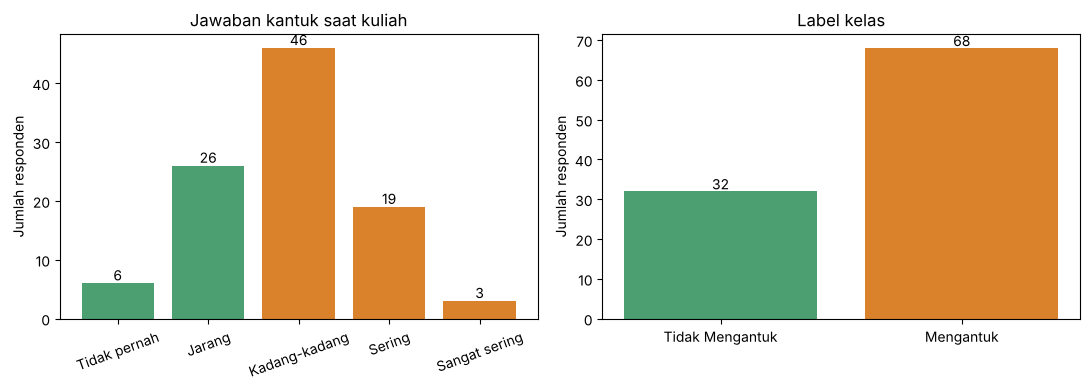

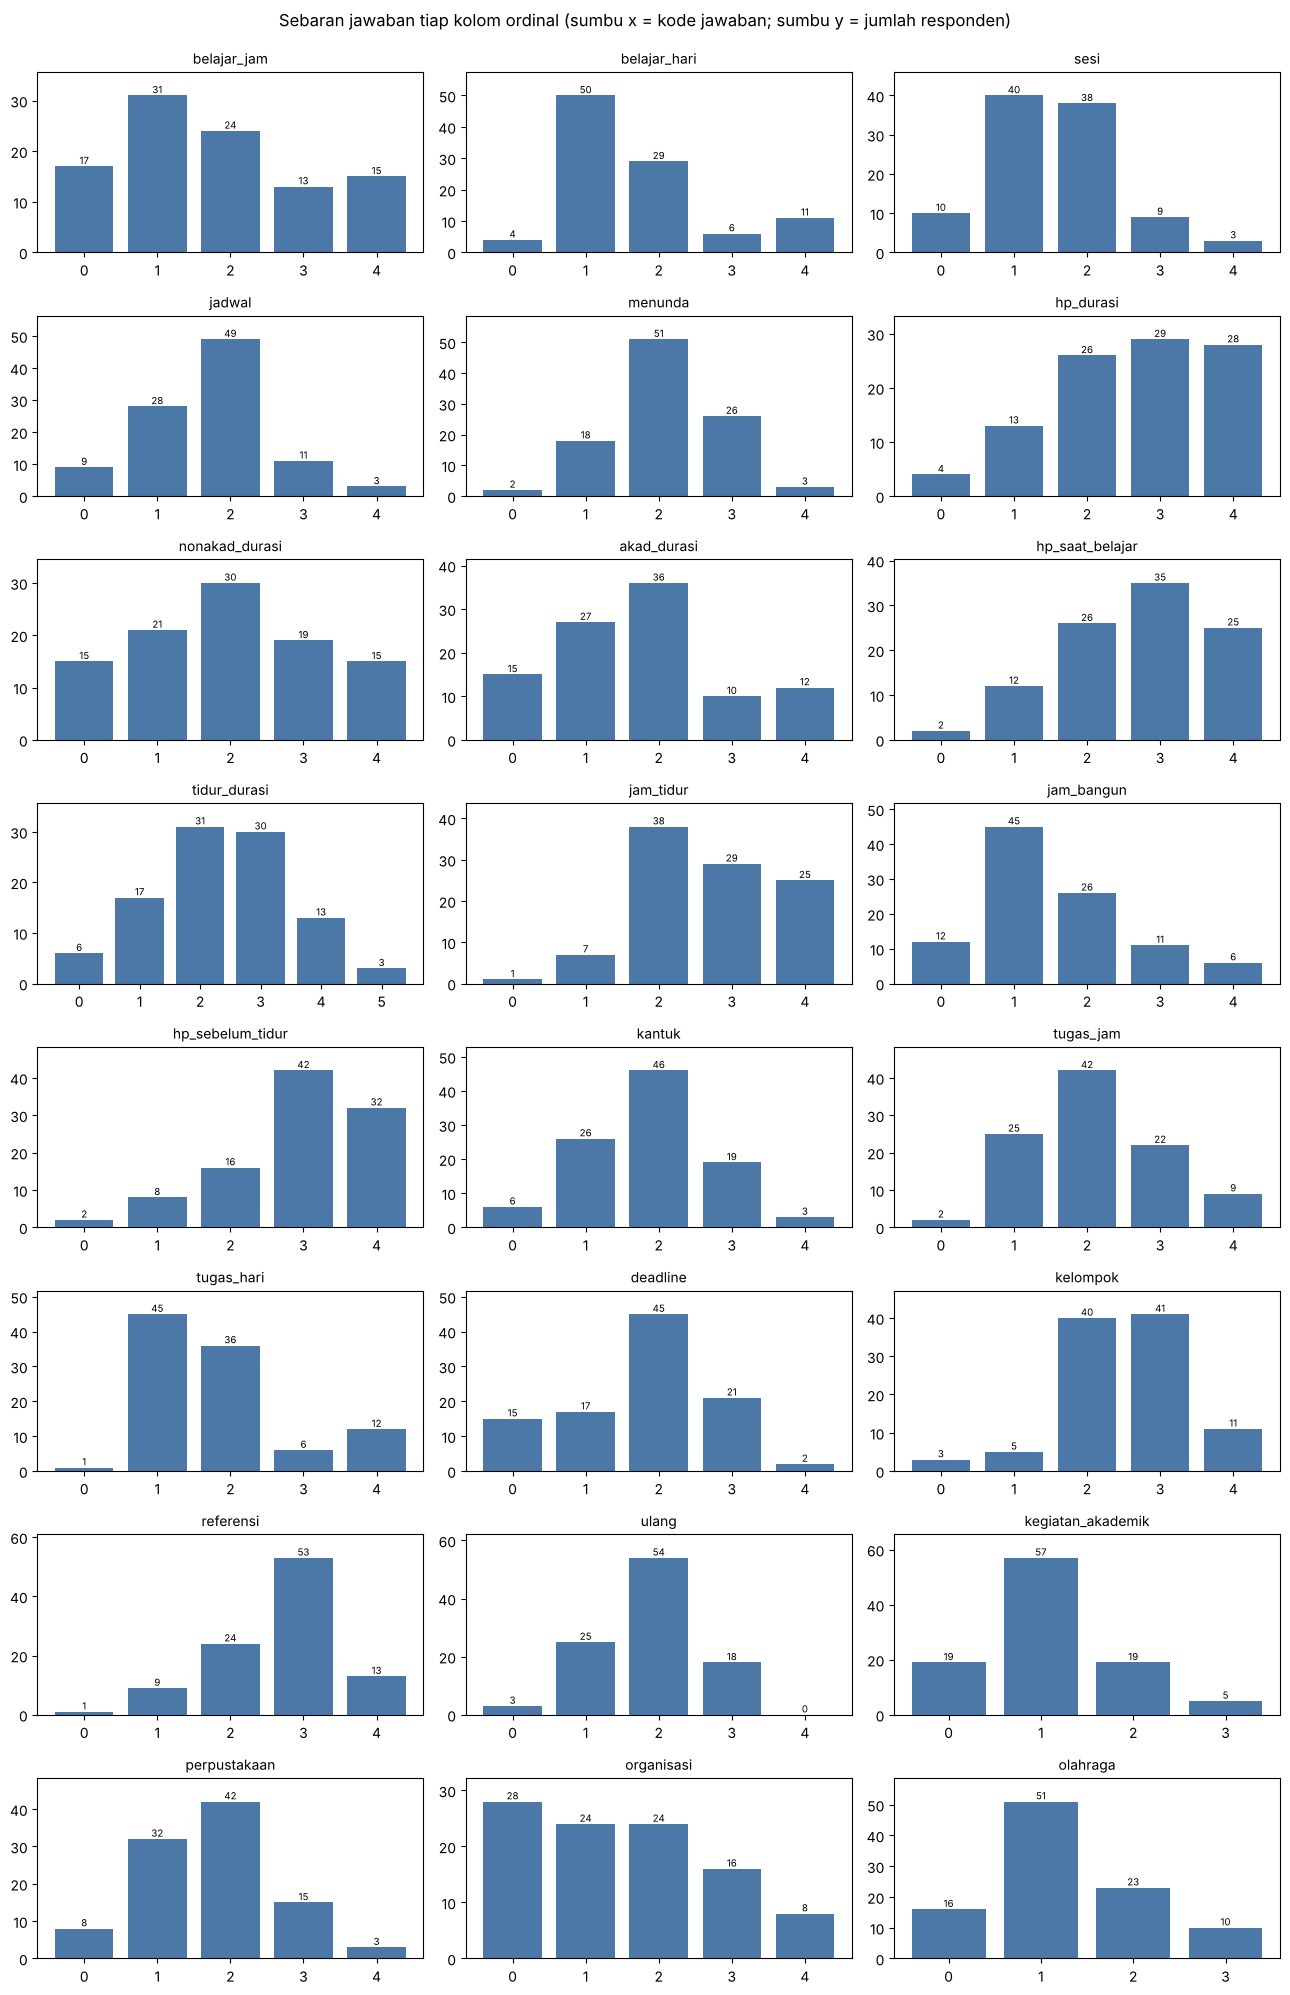

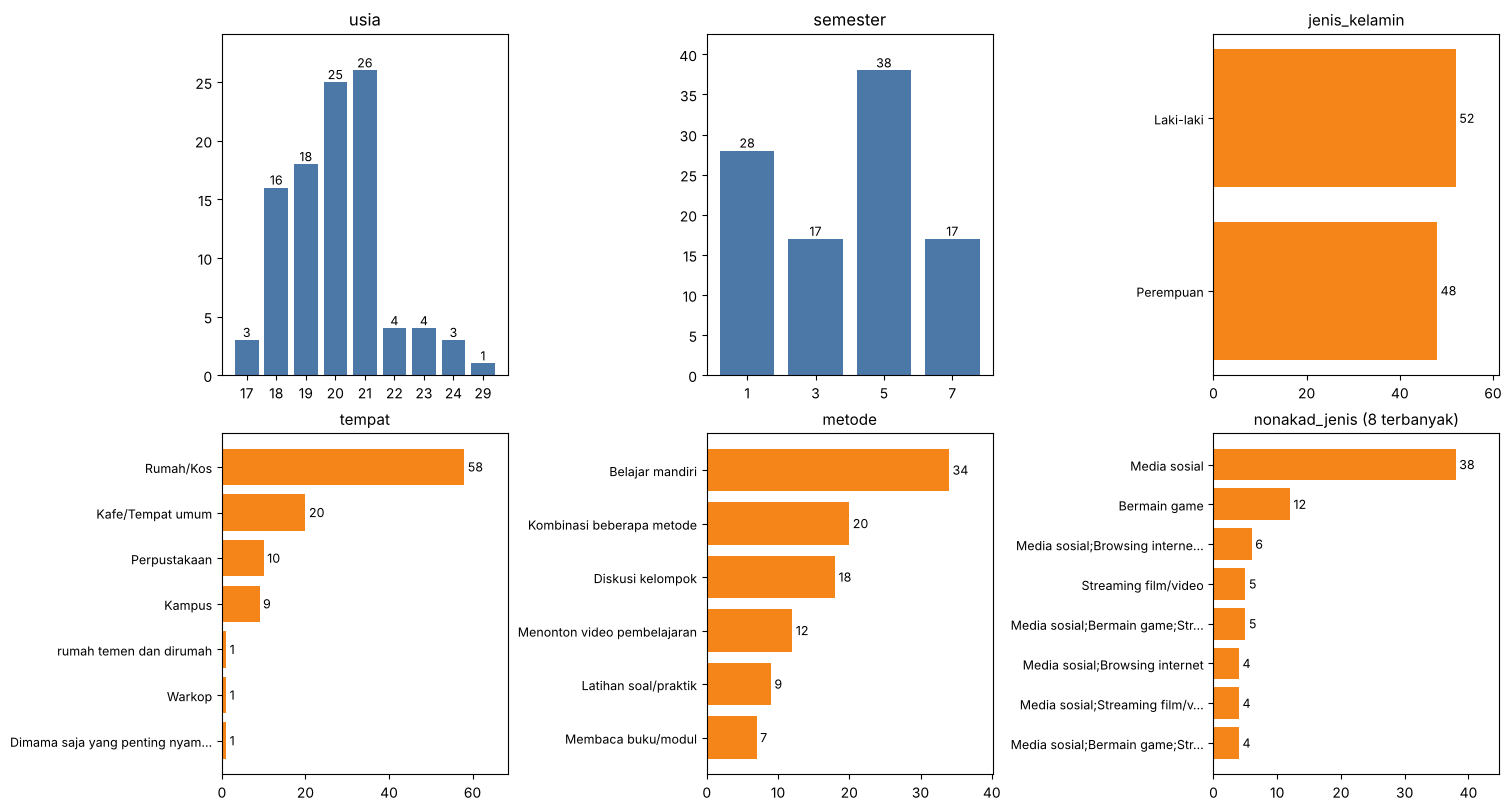

In [5]:
ORD = list(SKALA)                                   # 24 kolom ordinal (termasuk kantuk)
y_eda = (X_all["kantuk"] >= 2).astype(int)          # 1 = Mengantuk (kode kantuk 2 ke atas), 0 = Tidak Mengantuk
print("Responden aktif:", len(aktif), "| Mengantuk:", int(y_eda.sum()), "| Tidak Mengantuk:", int((1 - y_eda).sum()))

# T1b. Statistik deskriptif data terkode (rata-rata kode hanya ringkasan; jarak antar kode tidak dianggap sama)
r = []
for c in ORD + NUMERIK:
    s = X_all[c].astype(float); mo = int(s.mode().iloc[0])
    r.append([c, "Ordinal" if c in SKALA else "Numerik", int(s.count()), round(s.mean(), 2), round(s.median(), 1), round(s.std(), 2),
              int(s.min()), int(s.max()), mo, SKALA[c][mo] if c in SKALA else str(mo), round(float(stats.skew(s)), 2)])
t1b = pd.DataFrame(r, columns=["kolom", "jenis", "n", "rata2_kode", "median_kode", "simpangan_baku", "min", "maks", "modus_kode", "modus_jawaban", "kemencengan"])
print("Tabel T1b. Statistik deskriptif data terkode"); display(t1b)
t1b.to_csv("hasil/T1b_statistik_deskriptif.csv", index=False, encoding="utf-8-sig")

# T1c. Sebaran kolom nominal (tidak ikut PCA)
r = []
for c in ["jenis_kelamin", "tempat", "metode", "nonakad_jenis", "prodi"]:
    vc = aktif[c].value_counts()
    for k, v in vc.head(10).items(): r.append([c, k, int(v), round(v / len(aktif) * 100, 1)])
    r.append([c, f"(jumlah variasi tulisan: {len(vc)})", int(vc.iloc[10:].sum()) if len(vc) > 10 else 0, round(vc.iloc[10:].sum() / len(aktif) * 100, 1) if len(vc) > 10 else 0.0])
t1c = pd.DataFrame(r, columns=["kolom", "kategori", "n", "persen"])
print("Tabel T1c. Sebaran kolom nominal (10 kategori terbanyak; baris '(jumlah variasi...)' berisi sisa kategori)"); display(t1c)
t1c.to_csv("hasil/T1c_sebaran_nominal.csv", index=False, encoding="utf-8-sig")

# T1d. Persentase Mengantuk pada tiap jawaban (deskriptif; jumlah per jawaban kecil sehingga tidak boleh ditafsirkan sebagai pengaruh)
r = []
for c in ORD:
    if c == "kantuk": continue
    for kode, urut in enumerate(SKALA[c]):
        m = X_all[c] == kode; n = int(m.sum())
        r.append([c, kode, urut, n, int(y_eda[m].sum()), round(y_eda[m].mean() * 100, 1) if n else np.nan])
t1d = pd.DataFrame(r, columns=["kolom", "kode", "jawaban", "n", "n_mengantuk", "persen_mengantuk"])
print("Tabel T1d. Persentase Mengantuk pada tiap jawaban (12 baris pertama; selengkapnya di CSV)"); display(t1d.head(12))
t1d.to_csv("hasil/T1d_persen_mengantuk_per_jawaban.csv", index=False, encoding="utf-8-sig")

# G1. Sebaran jawaban kantuk dan label
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
cnt = X_all["kantuk"].value_counts().reindex(range(5), fill_value=0)
ax[0].bar(range(5), cnt.values, color=["#4C9F70"] * 2 + ["#D9822B"] * 3)
ax[0].set_xticks(range(5)); ax[0].set_xticklabels(SKALA["kantuk"], rotation=20); ax[0].set_ylabel("Jumlah responden"); ax[0].set_title("Jawaban kantuk saat kuliah")
for i, v in enumerate(cnt.values): ax[0].text(i, v + 0.5, str(v), ha="center")
lab = [int((1 - y_eda).sum()), int(y_eda.sum())]
ax[1].bar(["Tidak Mengantuk", "Mengantuk"], lab, color=["#4C9F70", "#D9822B"]); ax[1].set_title("Label kelas"); ax[1].set_ylabel("Jumlah responden")
for i, v in enumerate(lab): ax[1].text(i, v + 0.5, str(v), ha="center")
plt.tight_layout(); fig.savefig("hasil/G1_sebaran_label.png", dpi=200); plt.show()

# G1b. Sebaran jawaban tiap kolom ordinal (angka sumbu x = kode di tabel T2a)
fig, axs = plt.subplots(8, 3, figsize=(13, 20)); axs = axs.ravel()
for a, c in zip(axs, ORD):
    n_k = len(SKALA[c]); cc = X_all[c].value_counts().reindex(range(n_k), fill_value=0)
    a.bar(range(n_k), cc.values, color="#4C78A8"); a.set_title(c, fontsize=10); a.set_xticks(range(n_k))
    for i, v in enumerate(cc.values): a.text(i, v, str(v), ha="center", va="bottom", fontsize=7)
for a in axs[len(ORD):]: a.axis("off")
fig.suptitle("Sebaran jawaban tiap kolom ordinal (sumbu x = kode jawaban; sumbu y = jumlah responden)", y=0.995)
[a.margins(y=0.15) for a in axs[:len(ORD)]]; plt.tight_layout(); fig.savefig("hasil/G1b_sebaran_ordinal.png", dpi=150); plt.show()

# G1c. Sebaran usia, semester, dan kolom nominal (label panjang dipotong agar grafik terbaca)
def pendek(k, n=30): return k if len(k) <= n else k[:n - 1] + "…"
fig, axs = plt.subplots(2, 3, figsize=(15, 8), layout="constrained"); axs = axs.ravel()
for a, c in zip(axs[:2], ["usia", "semester"]):
    vc = X_all[c].value_counts().sort_index(); a.bar(vc.index.astype(str), vc.values, color="#4C78A8"); a.set_title(c); a.margins(y=0.12)
    for i, v in enumerate(vc.values): a.text(i, v, str(v), ha="center", va="bottom", fontsize=9)
for a, c in zip(axs[2:], ["jenis_kelamin", "tempat", "metode", "nonakad_jenis"]):
    vc = aktif[c].value_counts().head(8); pos = np.arange(len(vc))[::-1]
    a.barh(pos, vc.values, color="#F58518"); a.set_yticks(pos); a.set_yticklabels([pendek(k) for k in vc.index], fontsize=9)
    a.set_title(c + (" (8 terbanyak)" if aktif[c].nunique() > 8 else ""), fontsize=11); a.margins(x=0.18)
    for p, v in zip(pos, vc.values): a.text(v, p, f" {v}", va="center", fontsize=9)
fig.savefig("hasil/G1c_sebaran_profil.png", dpi=150); plt.show()


## Sel 5. Tahap 3: kelayakan PCA (korelasi, Bartlett, KMO, MSA)

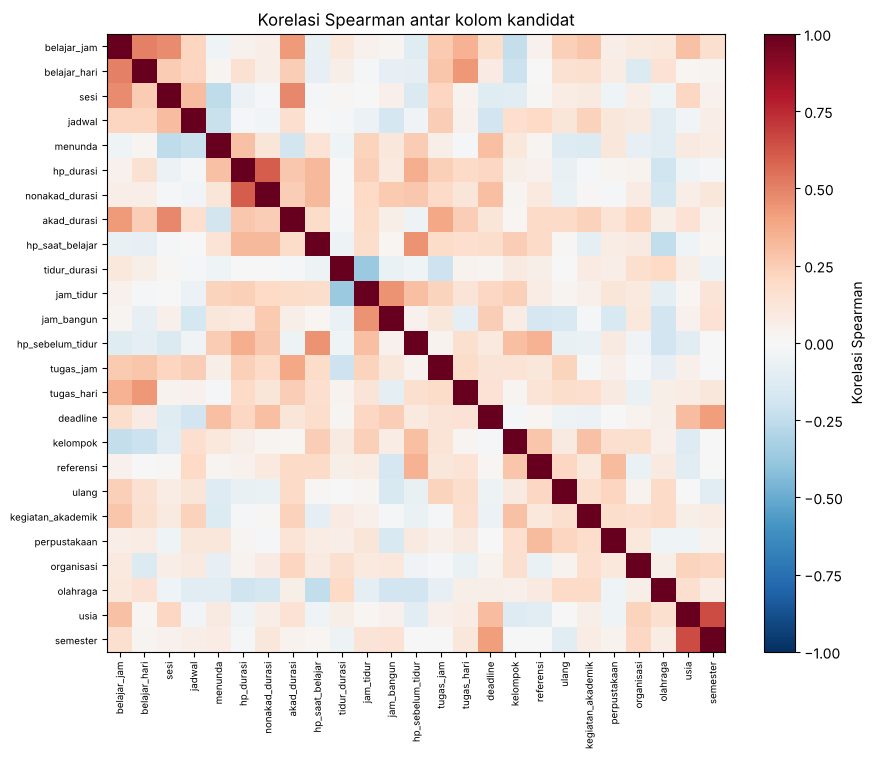

Tabel T3a. Kelayakan PCA


,Uji,Nilai,Kriteria
0,Bartlett chi-kuadrat,705.52,
1,Bartlett df,300,
2,Bartlett p-value,1.07e-34,"< 0,05 : PCA bermakna"
3,KMO keseluruhan,0.617,">= 0,5 : layak"


Tabel T3b. MSA per kolom (terurut dari terendah)


,kolom,MSA,status
9,tidur_durasi,0.361,"MSA < 0,5"
16,kelompok,0.496,"MSA < 0,5"
11,jam_bangun,0.503,
22,olahraga,0.524,
24,semester,0.533,
20,perpustakaan,0.549,
19,kegiatan_akademik,0.554,
23,usia,0.563,
4,menunda,0.564,
17,referensi,0.577,


Tabel T3c. 10 pasangan kolom berkorelasi terkuat


,kolom_1,kolom_2,rho
299,usia,semester,0.654
110,hp_durasi,nonakad_durasi,0.608
0,belajar_jam,belajar_hari,0.500
51,sesi,akad_durasi,0.482
1,belajar_jam,sesi,0.475
167,hp_saat_belajar,hp_sebelum_tidur,0.451
195,jam_tidur,jam_bangun,0.450
36,belajar_hari,tugas_hari,0.432
6,belajar_jam,akad_durasi,0.427
263,deadline,semester,0.418


Pasangan |rho| > 0,8: 0


In [6]:
n, p = X.shape
R = X.corr(method="spearman").values
kol = list(X.columns)
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(R, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(p)); ax.set_xticklabels(kol, rotation=90, fontsize=7)
ax.set_yticks(range(p)); ax.set_yticklabels(kol, fontsize=7)
plt.colorbar(im, label="Korelasi Spearman"); ax.set_title("Korelasi Spearman antar kolom kandidat")
plt.tight_layout(); fig.savefig("hasil/G3_korelasi.png", dpi=200); plt.show()

det = np.linalg.det(R)
chi2 = -(n - 1 - (2*p + 5)/6) * np.log(det); dfb = p*(p-1)/2; pb = stats.chi2.sf(chi2, dfb)
invR = np.linalg.inv(R)
A = -invR / np.sqrt(np.outer(np.diag(invR), np.diag(invR)))
np.fill_diagonal(A, 0); R0 = R.copy(); np.fill_diagonal(R0, 0)
msa = (R0**2).sum(0) / ((R0**2).sum(0) + (A**2).sum(0))
kmo = (R0**2).sum() / ((R0**2).sum() + (A**2).sum())
t3a = pd.DataFrame({"Uji": ["Bartlett chi-kuadrat", "Bartlett df", "Bartlett p-value", "KMO keseluruhan"],
                    "Nilai": [round(chi2,2), int(dfb), f"{pb:.2e}", round(kmo,3)],
                    "Kriteria": ["", "", "< 0,05 : PCA bermakna", ">= 0,5 : layak"]})
print("Tabel T3a. Kelayakan PCA"); display(t3a)
t3b = pd.DataFrame({"kolom": kol, "MSA": msa.round(3)}).sort_values("MSA")
t3b["status"] = np.where(t3b.MSA < 0.5, "MSA < 0,5", "")
print("Tabel T3b. MSA per kolom (terurut dari terendah)"); display(t3b)
pairs = [(kol[i], kol[j], round(R[i, j], 3)) for i in range(p) for j in range(i+1, p)]
t3c = pd.DataFrame(pairs, columns=["kolom_1","kolom_2","rho"])
t3c["abs"] = t3c.rho.abs(); t3c = t3c.sort_values("abs", ascending=False).drop(columns="abs")
print("Tabel T3c. 10 pasangan kolom berkorelasi terkuat"); display(t3c.head(10))
dup = t3c[t3c.rho.abs() > 0.8]
print("Pasangan |rho| > 0,8:", len(dup))
t3a.to_csv("hasil/T3a_kelayakan_pca.csv", index=False, encoding="utf-8-sig")
t3b.to_csv("hasil/T3b_msa.csv", index=False, encoding="utf-8-sig")
t3c.to_csv("hasil/T3c_pasangan_korelasi.csv", index=False, encoding="utf-8-sig")


## Sel 6. Tahap 4: PCA

In [7]:
ev, vec = np.linalg.eigh(R)
o = np.argsort(ev)[::-1]; ev, vec = ev[o], vec[:, o]
vec = vec * np.sign(vec[np.abs(vec).argmax(0), range(p)])     # tanda tetap: loading terbesar positif
load = vec * np.sqrt(ev)
from sklearn.decomposition import PCA
Rk = X.rank().values; Z = (Rk - Rk.mean(0)) / Rk.std(0, ddof=1)
print("Cocok dengan scikit-learn PCA:", np.allclose(PCA().fit(Z).explained_variance_, ev))
t4 = pd.DataFrame({"komponen": [f"PC{i+1}" for i in range(p)], "eigenvalue": ev.round(3),
                   "varians_%": (ev/p*100).round(2), "kumulatif_%": (np.cumsum(ev)/p*100).round(2)})
print("Tabel T4. Eigenvalue dan varians"); display(t4)
t4.to_csv("hasil/T4_eigenvalue.csv", index=False, encoding="utf-8-sig")


Cocok dengan scikit-learn PCA: True
Tabel T4. Eigenvalue dan varians


,komponen,eigenvalue,varians_%,kumulatif_%
0,PC1,3.475,13.90,13.90
1,PC2,3.028,12.11,26.01
2,PC3,2.309,9.23,35.25
3,PC4,1.855,7.42,42.67
4,PC5,1.637,6.55,49.21
5,PC6,1.380,5.52,54.73
6,PC7,1.222,4.89,59.62
7,PC8,1.039,4.16,63.78
8,PC9,0.982,3.93,67.71
9,PC10,0.884,3.54,71.24


## Sel 7. Tahap 5: jumlah komponen

Tabel T5. Jumlah komponen menurut tiga kriteria


,Kriteria,Jumlah komponen
0,Kaiser (eigenvalue > 1),8
1,Parallel analysis (persentil 95),5
2,Varians kumulatif >= 70%,10


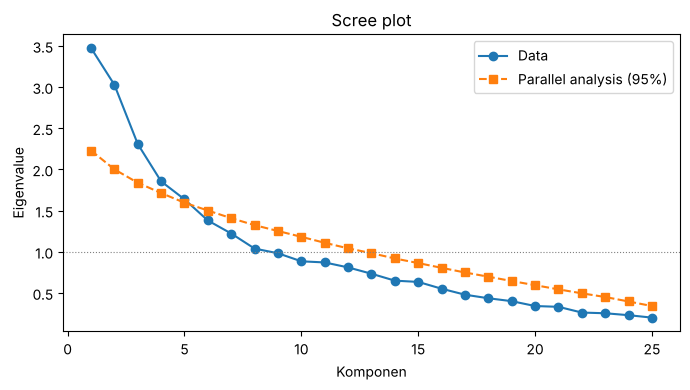

K yang dipakai (parallel analysis): 5


In [8]:
rng = np.random.default_rng(SEED)
B = 1000; sim = np.empty((B, p))
for b in range(B):
    Rp = np.column_stack([rng.permutation(Rk[:, j]) for j in range(p)])
    sim[b] = np.sort(np.linalg.eigvalsh(np.corrcoef(Rp, rowvar=False)))[::-1]
pa95 = np.percentile(sim, 95, axis=0)
K_pa = int(np.argmax(ev <= pa95)) if (ev <= pa95).any() else p
K_kaiser = int((ev > 1).sum())
K_var70 = int(np.searchsorted(np.cumsum(ev)/p, 0.70) + 1)
t5 = pd.DataFrame({"Kriteria": ["Kaiser (eigenvalue > 1)", "Parallel analysis (persentil 95)", "Varians kumulatif >= 70%"],
                   "Jumlah komponen": [K_kaiser, K_pa, K_var70]})
print("Tabel T5. Jumlah komponen menurut tiga kriteria"); display(t5)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, p+1), ev, "o-", label="Data")
ax.plot(range(1, p+1), pa95, "s--", label="Parallel analysis (95%)")
ax.axhline(1, color="grey", lw=0.8, ls=":")
ax.set_xlabel("Komponen"); ax.set_ylabel("Eigenvalue"); ax.set_title("Scree plot"); ax.legend()
plt.tight_layout(); fig.savefig("hasil/G5_scree.png", dpi=200); plt.show()
t5.to_csv("hasil/T5_jumlah_komponen.csv", index=False, encoding="utf-8-sig")
K = K_pa
print("K yang dipakai (parallel analysis):", K)


## Sel 8. Tahap 6: keputusan tiap kolom

Tabel T6. Keputusan tiap kolom (K = 5 komponen)


,kolom,communality,loading_maks,komponen_dominan,MSA,keputusan,alasan
0,belajar_jam,0.681,0.560,PC2,0.707,Dipertahankan,"communality 0.681 dan loading 0.56 >= 0,40"
1,usia,0.659,0.640,PC3,0.563,Dipertahankan,"communality 0.659 dan loading 0.64 >= 0,40"
2,belajar_hari,0.641,0.432,PC2,0.658,Dipertahankan,"communality 0.641 dan loading 0.432 >= 0,40"
3,kelompok,0.633,0.493,PC4,0.496,Calon dibuang,"MSA 0.496 < 0,5"
4,semester,0.621,0.576,PC3,0.533,Dipertahankan,"communality 0.621 dan loading 0.576 >= 0,40"
5,akad_durasi,0.591,0.657,PC1,0.682,Dipertahankan,"communality 0.591 dan loading 0.657 >= 0,40"
6,deadline,0.589,0.494,PC3,0.715,Dipertahankan,"communality 0.589 dan loading 0.494 >= 0,40"
7,sesi,0.588,0.516,PC2,0.632,Dipertahankan,"communality 0.588 dan loading 0.516 >= 0,40"
8,hp_sebelum_tidur,0.558,0.580,PC2,0.704,Dipertahankan,"communality 0.558 dan loading 0.58 >= 0,40"
9,hp_durasi,0.551,0.533,PC1,0.638,Dipertahankan,"communality 0.551 dan loading 0.533 >= 0,40"


{'Dipertahankan': 19, 'Zona abu-abu': 4, 'Calon dibuang': 2}


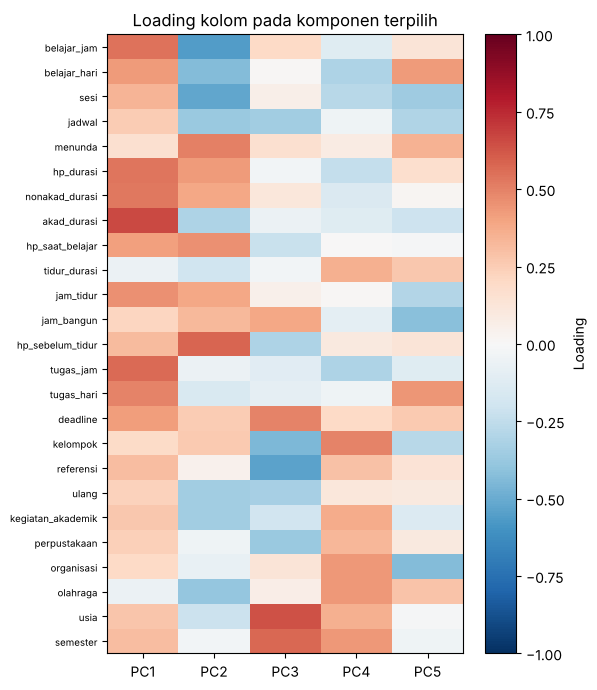

In [9]:
h2 = (load[:, :K]**2).sum(1)
mx = np.abs(load[:, :K]).max(1)
pc_mx = np.abs(load[:, :K]).argmax(1) + 1
t6 = pd.DataFrame({"kolom": kol, "communality": h2.round(3), "loading_maks": mx.round(3),
                   "komponen_dominan": [f"PC{i}" for i in pc_mx], "MSA": msa.round(3)})
def putus(r):
    if r.MSA < 0.5 or r.communality < 0.30:
        return "Calon dibuang"
    if r.communality >= 0.40 and r.loading_maks >= 0.40:
        return "Dipertahankan"
    return "Zona abu-abu"
t6["keputusan"] = t6.apply(putus, axis=1)
def alasan(r):
    a = []
    if r.MSA < 0.5: a.append(f"MSA {r.MSA} < 0,5")
    if r.communality < 0.30: a.append(f"communality {r.communality} < 0,30")
    if not a and r.keputusan == "Dipertahankan": a.append(f"communality {r.communality} dan loading {r.loading_maks} >= 0,40")
    if not a: a.append(f"communality {r.communality}, loading {r.loading_maks} (di antara ambang)")
    return "; ".join(a)
t6["alasan"] = t6.apply(alasan, axis=1)
t6 = t6.sort_values("communality", ascending=False).reset_index(drop=True)
print("Tabel T6. Keputusan tiap kolom (K =", K, "komponen)"); display(t6)
print(t6.keputusan.value_counts().to_dict())
fig, ax = plt.subplots(figsize=(6, 7))
im = ax.imshow(load[:, :K], cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_yticks(range(p)); ax.set_yticklabels(kol, fontsize=7); ax.set_xticks(range(K)); ax.set_xticklabels([f"PC{i+1}" for i in range(K)])
plt.colorbar(im, label="Loading"); ax.set_title("Loading kolom pada komponen terpilih")
plt.tight_layout(); fig.savefig("hasil/G6_loading.png", dpi=200); plt.show()
t6.to_csv("hasil/T6_keputusan_kolom.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(load[:, :K], index=kol, columns=[f"PC{i+1}" for i in range(K)]).round(3).to_csv("hasil/T6b_loading.csv", encoding="utf-8-sig")


## Sel 9. Tahap 7a: definisi label dan fungsi analisis

In [10]:
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import CategoricalNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score, f1_score
from sklearn.feature_selection import mutual_info_classif

# Label: Mengantuk bila kantuk >= "Kadang-kadang" (kode 2)
LABEL = {
    "B": dict(nama="Mengantuk / Tidak Mengantuk", kolom="kantuk", y=(X_all.kantuk >= 2).astype(int).values,
              kelas=["Tidak Mengantuk", "Mengantuk"], keluar=["kantuk"]),
}
KANDIDAT = list(SKALA) + NUMERIK        # 26 kolom ordinal + numerik (nominal tidak ikut, sesuai Tahap 0)
Q_AMBANG = 0.10                          # ambang FDR (Benjamini-Hochberg) untuk mengembalikan kolom

def bh(pv):
    pv = np.asarray(pv, float); m = len(pv); o = np.argsort(pv)
    q = np.empty(m); prev = 1.0
    for rank, idx in zip(range(m, 0, -1), o[::-1]):
        prev = min(prev, pv[idx] * m / rank); q[idx] = prev
    return q

def pca_keputusan(Xp, K_paksa=None):
    """Ulang Tahap 3-6 untuk himpunan kolom Xp (tanpa label)."""
    n, p = Xp.shape; kol = list(Xp.columns)
    R = Xp.corr(method="spearman").values
    invR = np.linalg.inv(R)
    A = -invR / np.sqrt(np.outer(np.diag(invR), np.diag(invR))); np.fill_diagonal(A, 0)
    R0 = R.copy(); np.fill_diagonal(R0, 0)
    msa = (R0**2).sum(0) / ((R0**2).sum(0) + (A**2).sum(0))
    kmo = (R0**2).sum() / ((R0**2).sum() + (A**2).sum())
    pb = stats.chi2.sf(-(n - 1 - (2*p + 5)/6) * np.log(np.linalg.det(R)), p*(p-1)/2)
    ev, vec = np.linalg.eigh(R); o = np.argsort(ev)[::-1]; ev, vec = ev[o], vec[:, o]
    vec = vec * np.sign(vec[np.abs(vec).argmax(0), range(p)]); load = vec * np.sqrt(ev)
    if K_paksa is None:
        Rk = Xp.rank().values; rng = np.random.default_rng(SEED); sim = np.empty((1000, p))
        for b in range(1000):
            Rp = np.column_stack([rng.permutation(Rk[:, j]) for j in range(p)])
            sim[b] = np.sort(np.linalg.eigvalsh(np.corrcoef(Rp, rowvar=False)))[::-1]
        pa95 = np.percentile(sim, 95, axis=0)
        K = int(np.argmax(ev <= pa95)) if (ev <= pa95).any() else p
    else:
        K = int(K_paksa)
    h2 = (load[:, :K]**2).sum(1); mx = np.abs(load[:, :K]).max(1)
    t = pd.DataFrame({"kolom": kol, "communality": h2.round(3), "loading_maks": mx.round(3), "MSA": msa.round(3)})
    def putus(r):
        if r.MSA < 0.5 or r.communality < 0.30: return "Calon dibuang"
        if r.communality >= 0.40 and r.loading_maks >= 0.40: return "Dipertahankan"
        return "Zona abu-abu"
    t["keputusan_PCA"] = t.apply(putus, axis=1)
    return t, dict(K=K, kmo=round(kmo, 3), p_bartlett=pb, kaiser=int((ev > 1).sum()), n=n, p=p,
                   var_K=round(float(ev[:K].sum()/p*100), 1))

def hubungan(Xp, y):
    r, pv = [], []
    for c in Xp.columns:
        rho, pval = stats.spearmanr(Xp[c], y); r.append(rho); pv.append(pval)
    mi = mutual_info_classif(Xp.values.astype(int), y, discrete_features=True, random_state=SEED)
    t = pd.DataFrame({"kolom": Xp.columns, "rho_dengan_label": np.round(r, 3), "p_value": np.round(pv, 4),
                      "q_BH": np.round(bh(pv), 4), "mutual_info": np.round(mi, 4)})
    return t

def buat_model(nm, Xp):
    if nm == "Decision Tree": return DecisionTreeClassifier(criterion="entropy", max_depth=3, min_samples_leaf=5, random_state=SEED)
    if nm == "Naive Bayes":   return CategoricalNB(alpha=1.0, min_categories=(Xp.max(axis=0).values.astype(int) + 1))
    return RandomForestClassifier(n_estimators=300, max_depth=4, random_state=SEED, n_jobs=-1)

def cv_bandingkan(Xp, y, dipertahankan, lainnya):
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
    hasil = []
    for tr, te in cv.split(Xp, y):
        Xtr, Xte, ytr, yte = Xp.iloc[tr], Xp.iloc[te], y[tr], y[te]
        pv = [stats.spearmanr(Xtr[c], ytr)[1] for c in lainnya]            # pengembalian dihitung HANYA dari data latih
        kembali = [c for c, q in zip(lainnya, bh(pv)) if q < Q_AMBANG] if lainnya else []
        himpunan = {"Semua kolom": list(Xp.columns), "Hasil PCA": dipertahankan, "PCA + dikembalikan": dipertahankan + kembali}
        mayor = int(np.bincount(ytr).argmax())
        hasil.append(["-", "Mayoritas", (yte == mayor).mean(), balanced_accuracy_score(yte, np.full_like(yte, mayor)),
                      f1_score(yte, np.full_like(yte, mayor), average="macro", zero_division=0), len(Xp.columns)])
        for hs, cols in himpunan.items():
            for nm in ["Decision Tree", "Naive Bayes", "Random Forest"]:
                m = buat_model(nm, Xp[cols]).fit(Xtr[cols].values, ytr); pr = m.predict(Xte[cols].values)
                hasil.append([hs, nm, (pr == yte).mean(), balanced_accuracy_score(yte, pr),
                              f1_score(yte, pr, average="macro", zero_division=0), len(cols)])
    h = pd.DataFrame(hasil, columns=["himpunan", "model", "akurasi", "akurasi_seimbang", "F1_makro", "jml_kolom"])
    g = h.groupby(["himpunan", "model"], sort=False).agg(akurasi=("akurasi", "mean"), sd=("akurasi", "std"),
        akurasi_seimbang=("akurasi_seimbang", "mean"), F1_makro=("F1_makro", "mean"), rata_jml_kolom=("jml_kolom", "mean")).round(3)
    return g.reset_index()

def jalankan_label(kode):
    L = LABEL[kode]; y = L["y"]
    pool = [c for c in KANDIDAT if c not in L["keluar"]]
    Xp = X_all[pool].astype(float)
    print(f"=== LABEL {kode}: {L['nama']} | {L['kelas'][1]} = {int(y.sum())}, {L['kelas'][0]} = {int((1-y).sum())} | kolom kandidat = {len(pool)} (n/p = {len(y)/len(pool):.2f}) ===")
    print("Kolom keluar dari kandidat:", L["keluar"])
    t, info = pca_keputusan(Xp)
    print(f"PCA ulang: KMO {info['kmo']}, Bartlett p {info['p_bartlett']:.2e}, K (parallel analysis) {info['K']}, Kaiser {info['kaiser']}, varians K komponen {info['var_K']}%")
    h = hubungan(Xp, y)
    d = t.merge(h, on="kolom")
    def final(r):
        if r.keputusan_PCA == "Dipertahankan": return "Dipakai (PCA)"
        return "Dikembalikan (berhubungan dengan label)" if r.q_BH < Q_AMBANG else "Dibuang"
    d["keputusan_akhir"] = d.apply(final, axis=1)
    d = d.sort_values(["keputusan_akhir", "communality"], ascending=[True, False]).reset_index(drop=True)
    print(f"Tabel T7a_{kode}. Keputusan akhir tiap kolom (PCA lalu pengaman label)"); display(d)
    print(d.keputusan_akhir.value_counts().to_dict())
    d.to_csv(f"hasil/T7a_{kode}_keputusan_akhir.csv", index=False, encoding="utf-8-sig")
    dip = d[d.keputusan_PCA == "Dipertahankan"].kolom.tolist()
    lain = d[d.keputusan_PCA != "Dipertahankan"].kolom.tolist()
    g = cv_bandingkan(Xp, y, dip, lain)
    print(f"Tabel T7b_{kode}. Perbandingan akurasi (validasi silang 5-lipat x 10 ulangan)"); display(g)
    g.to_csv(f"hasil/T7b_{kode}_perbandingan_model.csv", index=False, encoding="utf-8-sig")
    fig, ax = plt.subplots(figsize=(7.5, 4))
    mm = g[g.himpunan != "-"]; hs = list(dict.fromkeys(mm.himpunan)); w = 0.25
    for i, nm in enumerate(["Decision Tree", "Naive Bayes", "Random Forest"]):
        v = mm[mm.model == nm].set_index("himpunan").loc[hs]
        ax.bar(np.arange(len(hs)) + (i-1)*w, v.akurasi, w, yerr=v.sd, label=nm, capsize=2)
    ax.axhline(g[g.model == "Mayoritas"].akurasi.iloc[0], color="red", ls="--", lw=1, label="Mayoritas")
    ax.set_xticks(range(len(hs))); ax.set_xticklabels(hs); ax.set_ylim(0.3, 1); ax.set_ylabel("Akurasi")
    ax.set_title(L["nama"]); ax.legend(fontsize=8)
    plt.tight_layout(); fig.savefig(f"hasil/G7_{kode}_perbandingan.png", dpi=200); plt.show()
    return d, g
print("Fungsi siap. Lanjut ke sel berikutnya.")


Fungsi siap. Lanjut ke sel berikutnya.


## Sel 10. Tahap 7b: seleksi kolom dan perbandingan (butuh beberapa menit)

=== LABEL B: Mengantuk / Tidak Mengantuk | Mengantuk = 68, Tidak Mengantuk = 32 | kolom kandidat = 25 (n/p = 4.00) ===
Kolom keluar dari kandidat: ['kantuk']


PCA ulang: KMO 0.617, Bartlett p 1.07e-34, K (parallel analysis) 5, Kaiser 8, varians K komponen 49.2%
Tabel T7a_B. Keputusan akhir tiap kolom (PCA lalu pengaman label)


,kolom,communality,loading_maks,MSA,keputusan_PCA,rho_dengan_label,p_value,q_BH,mutual_info,keputusan_akhir
0,kelompok,0.633,0.493,0.496,Calon dibuang,0.010,0.9215,0.9937,0.0091,Dibuang
1,jadwal,0.415,0.374,0.589,Zona abu-abu,0.049,0.6290,0.9937,0.0017,Dibuang
2,kegiatan_akademik,0.385,0.370,0.554,Zona abu-abu,0.037,0.7184,0.9937,0.0149,Dibuang
3,perpustakaan,0.314,0.369,0.549,Zona abu-abu,0.028,0.7855,0.9937,0.0180,Dibuang
4,ulang,0.305,0.346,0.716,Zona abu-abu,-0.064,0.5248,0.9937,0.0083,Dibuang
5,tidur_durasi,0.242,0.352,0.361,Calon dibuang,-0.143,0.1553,0.5362,0.0127,Dibuang
6,belajar_jam,0.681,0.560,0.707,Dipertahankan,0.092,0.3646,0.9115,0.0068,Dipakai (PCA)
7,usia,0.659,0.640,0.563,Dipertahankan,0.084,0.4066,0.9241,0.0272,Dipakai (PCA)
8,belajar_hari,0.641,0.432,0.658,Dipertahankan,0.058,0.5636,0.9937,0.0042,Dipakai (PCA)
9,semester,0.621,0.576,0.533,Dipertahankan,0.235,0.0188,0.4692,0.0464,Dipakai (PCA)


{'Dipakai (PCA)': 19, 'Dibuang': 6}


Tabel T7b_B. Perbandingan akurasi (validasi silang 5-lipat x 10 ulangan)


,himpunan,model,akurasi,sd,akurasi_seimbang,F1_makro,rata_jml_kolom
0,-,Mayoritas,0.680,0.025,0.500,0.405,25.0
1,Semua kolom,Decision Tree,0.612,0.104,0.509,0.491,25.0
2,Semua kolom,Naive Bayes,0.576,0.085,0.476,0.461,25.0
3,Semua kolom,Random Forest,0.672,0.049,0.512,0.450,25.0
4,Hasil PCA,Decision Tree,0.626,0.095,0.519,0.497,19.0
5,Hasil PCA,Naive Bayes,0.614,0.090,0.507,0.493,19.0
6,Hasil PCA,Random Forest,0.694,0.040,0.540,0.493,19.0
7,PCA + dikembalikan,Decision Tree,0.626,0.095,0.519,0.497,19.0
8,PCA + dikembalikan,Naive Bayes,0.614,0.090,0.507,0.493,19.0
9,PCA + dikembalikan,Random Forest,0.694,0.040,0.540,0.493,19.0


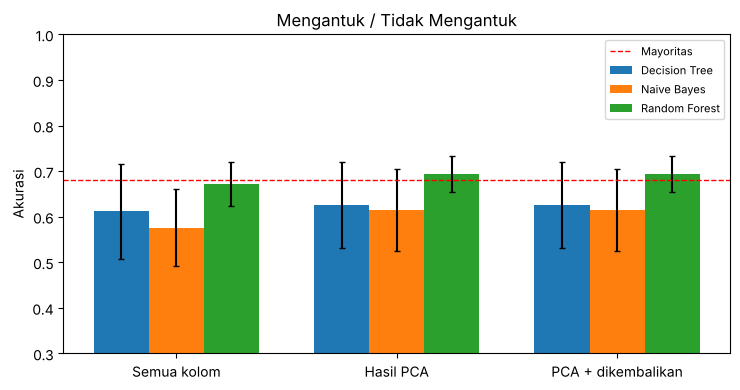

In [11]:
dB, gB = jalankan_label("B")


## Sel 11. Tahap 8: model final dan evaluasi

=== TAHAP 8, LABEL B: Mengantuk / Tidak Mengantuk | 19 fitur final ===
Fitur: ['belajar_jam', 'usia', 'belajar_hari', 'semester', 'akad_durasi', 'deadline', 'sesi', 'hp_sebelum_tidur', 'hp_durasi', 'jam_bangun', 'referensi', 'tugas_hari', 'nonakad_durasi', 'jam_tidur', 'tugas_jam', 'organisasi', 'menunda', 'hp_saat_belajar', 'olahraga']


Tabel T8a. Ringkasan (validasi silang 5-lipat x 10 ulangan)


,model,akurasi,sd,akurasi_seimbang,F1_makro
0,Mayoritas,0.680,0.025,0.500,NaN
1,Decision Tree,0.626,0.095,0.519,0.497
2,Naive Bayes,0.614,0.090,0.507,0.493
3,Random Forest,0.694,0.040,0.540,0.493


Tabel T8b. Precision, recall, F1 per kelas (dari confusion matrix rata-rata 10 ulangan)


,model,kelas,precision,recall,F1,jumlah_sebenarnya
0,Decision Tree,Tidak Mengantuk,0.361,0.219,0.272,32
1,Decision Tree,Mengantuk,0.690,0.818,0.748,68
2,Naive Bayes,Tidak Mengantuk,0.335,0.209,0.258,32
3,Naive Bayes,Mengantuk,0.684,0.804,0.739,68
4,Random Forest,Tidak Mengantuk,0.621,0.112,0.190,32
5,Random Forest,Mengantuk,0.699,0.968,0.811,68


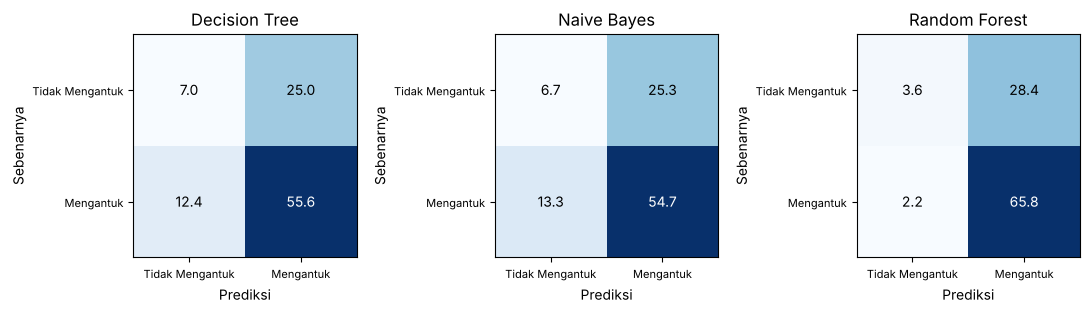

Tabel T8c. Information gain terbaik tiap fitur (10 teratas dari 19)


,fitur,ambang,n_kiri,n_kanan,gain
0,semester,1.0,28,72,0.0577
1,deadline,1.0,32,68,0.0491
2,organisasi,1.0,52,48,0.0389
3,olahraga,2.0,90,10,0.0267
4,hp_durasi,1.0,17,83,0.0153
5,jam_tidur,2.0,46,54,0.0144
6,tugas_jam,2.0,69,31,0.0137
7,usia,22.0,92,8,0.0128
8,referensi,2.0,34,66,0.0126
9,hp_sebelum_tidur,1.0,10,90,0.0112


Hitung manual fitur teratas (semester <= 1): entropy akar 0.9044; kiri n=28 entropy 0.9963; kanan n=72 entropy 0.7885; gain = 0.9044 - (28/100 x 0.9963 + 72/100 x 0.7885) = 0.0577
Akar pohon scikit-learn: semester (<= 2.0), gain 0.0577; cocok dengan hitung manual: True
|--- semester <= 2.00
|   |--- olahraga <= 2.50
|   |   |--- hp_sebelum_tidur <= 2.50
|   |   |   |--- class: 0
|   |   |--- hp_sebelum_tidur >  2.50
|   |   |   |--- class: 1
|   |--- olahraga >  2.50
|   |   |--- class: 0
|--- semester >  2.00
|   |--- jam_bangun <= 1.50
|   |   |--- tugas_hari <= 1.50
|   |   |   |--- class: 1
|   |   |--- tugas_hari >  1.50
|   |   |   |--- class: 1
|   |--- jam_bangun >  1.50
|   |   |--- jam_bangun <= 3.50
|   |   |   |--- class: 1
|   |   |--- jam_bangun >  3.50
|   |   |   |--- class: 1



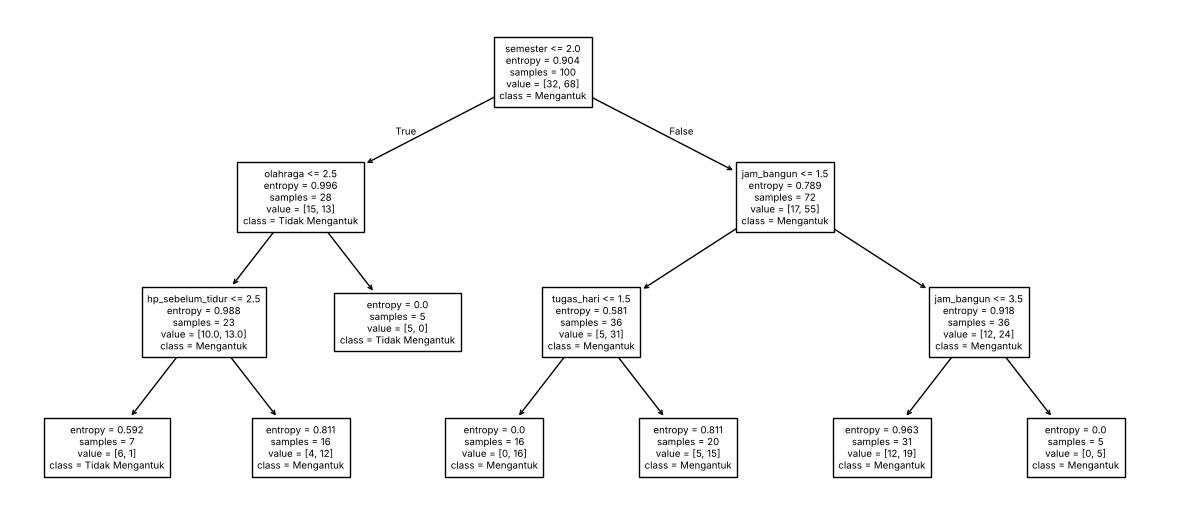

Tabel T8d. Naive Bayes manual untuk responden #1 (label asli: Tidak Mengantuk)


,fitur,kode_responden_1,P(fitur | Tidak Mengantuk),P(fitur | Mengantuk)
0,belajar_jam,1,0.3243,0.2877
1,usia,20,0.1290,0.1939
2,belajar_hari,2,0.2432,0.3014
3,semester,5,0.3000,0.3684
4,akad_durasi,3,0.1351,0.0959
5,deadline,2,0.2703,0.5068
6,sesi,2,0.3784,0.3562
7,hp_sebelum_tidur,1,0.1351,0.0685
8,hp_durasi,2,0.3243,0.2192
9,jam_bangun,2,0.2973,0.2329


Posterior manual: Tidak Mengantuk 0.5027, Mengantuk 0.4973 | scikit-learn: 0.5027, 0.4973 | cocok: True


Tabel T8e. Kepentingan fitur Random Forest (10 teratas)


,fitur,kepentingan
0,organisasi,0.084
1,deadline,0.083
2,semester,0.082
3,olahraga,0.081
4,menunda,0.066
5,hp_sebelum_tidur,0.058
6,jam_tidur,0.053
7,usia,0.052
8,jam_bangun,0.050
9,tugas_jam,0.050


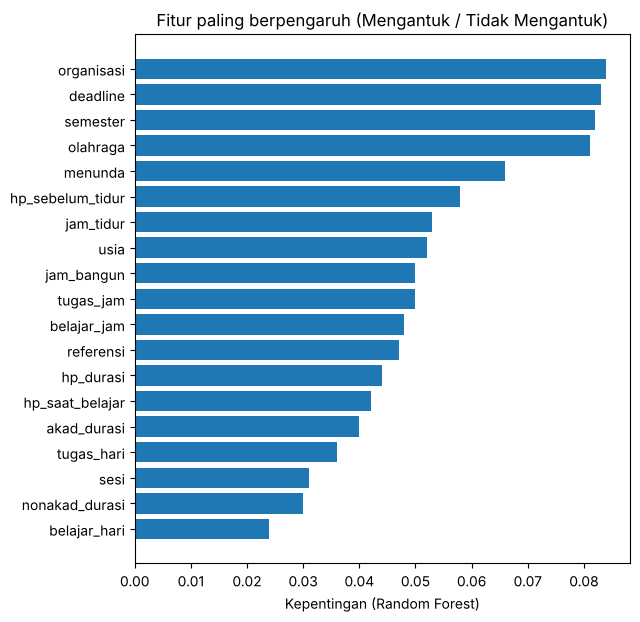

In [12]:
from sklearn.tree import plot_tree, export_text
from sklearn.metrics import confusion_matrix

def fitur_final(d):
    return d[d.keputusan_akhir != "Dibuang"].kolom.tolist()

def entropi(y):
    p = np.bincount(y, minlength=2) / len(y); p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

def gain_terbaik(x, y, min_daun=5):
    best = None
    for t in np.unique(x)[:-1]:
        kiri = x <= t; nk = int(kiri.sum()); nr = len(x) - nk
        if nk < min_daun or nr < min_daun: continue
        g = entropi(y) - (nk/len(y) * entropi(y[kiri]) + nr/len(y) * entropi(y[~kiri]))
        if best is None or g > best["gain"]:
            best = dict(ambang=float(t), n_kiri=nk, n_kanan=nr, gain=float(g))
    return best

def evaluasi_cv(Xf, y, nm, n_repeats=10):
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=n_repeats, random_state=SEED)
    a, b, f, cm = [], [], [], np.zeros((2, 2))
    for tr, te in cv.split(Xf, y):
        m = buat_model(nm, Xf).fit(Xf.iloc[tr].values, y[tr]); pr = m.predict(Xf.iloc[te].values)
        a.append((pr == y[te]).mean()); b.append(balanced_accuracy_score(y[te], pr))
        f.append(f1_score(y[te], pr, average="macro", zero_division=0))
        cm += confusion_matrix(y[te], pr, labels=[0, 1])
    return np.array(a), np.array(b), np.array(f), cm / n_repeats

HASIL8 = {}
def tahap8(kode, d):
    L = LABEL[kode]; y = L["y"]; kelas = L["kelas"]
    fit = fitur_final(d); Xf = X_all[fit].astype(float)
    print(f"=== TAHAP 8, LABEL {kode}: {L['nama']} | {len(fit)} fitur final ===")
    print("Fitur:", fit)
    # --- ringkasan dan per kelas
    ring, per, cms = [], [], {}
    mayor = []
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
    for tr, te in cv.split(Xf, y):
        mc = int(np.bincount(y[tr]).argmax()); mayor.append((y[te] == mc).mean())
    ring.append(["Mayoritas", np.mean(mayor), np.std(mayor, ddof=1), 0.5, np.nan])
    for nm in ["Decision Tree", "Naive Bayes", "Random Forest"]:
        a, b, f, cm = evaluasi_cv(Xf, y, nm); cms[nm] = cm
        ring.append([nm, a.mean(), a.std(ddof=1), b.mean(), f.mean()])
        for k in (0, 1):
            pr_ = cm[k, k] / cm[:, k].sum() if cm[:, k].sum() else np.nan; rc = cm[k, k] / cm[k, :].sum()
            per.append([nm, kelas[k], round(pr_, 3), round(rc, 3), round(2*pr_*rc/(pr_+rc), 3) if pr_ + rc else np.nan, int(round(cm[k, :].sum()))])
    t8a = pd.DataFrame(ring, columns=["model", "akurasi", "sd", "akurasi_seimbang", "F1_makro"]).round(3)
    t8b = pd.DataFrame(per, columns=["model", "kelas", "precision", "recall", "F1", "jumlah_sebenarnya"])
    print("Tabel T8a. Ringkasan (validasi silang 5-lipat x 10 ulangan)"); display(t8a)
    print("Tabel T8b. Precision, recall, F1 per kelas (dari confusion matrix rata-rata 10 ulangan)"); display(t8b)
    t8a.to_csv(f"hasil/T8a_{kode}_ringkasan_model.csv", index=False, encoding="utf-8-sig")
    t8b.to_csv(f"hasil/T8b_{kode}_per_kelas.csv", index=False, encoding="utf-8-sig")
    fig, axs = plt.subplots(1, 3, figsize=(11, 3.6))
    for ax, nm in zip(axs, cms):
        cm = cms[nm]; ax.imshow(cm, cmap="Blues")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm[i, j]:.1f}", ha="center", va="center", color="white" if cm[i, j] > (cm.min() + cm.max())/2 else "black")
        ax.set_xticks([0, 1]); ax.set_xticklabels(kelas, fontsize=8); ax.set_yticks([0, 1]); ax.set_yticklabels(kelas, fontsize=8)
        ax.set_xlabel("Prediksi"); ax.set_ylabel("Sebenarnya"); ax.set_title(nm)
    plt.tight_layout(); fig.savefig(f"hasil/G8_{kode}_confusion.png", dpi=200); plt.show()
    # --- information gain manual dan pohon
    gt = []
    for c in fit:
        g = gain_terbaik(Xf[c].values.astype(int), y)
        if g: gt.append(dict(fitur=c, **g))
    t8c = pd.DataFrame(gt).sort_values("gain", ascending=False).reset_index(drop=True).round(4)
    top = t8c.iloc[0]; kiri = Xf[top.fitur].values <= top.ambang
    H0, Hk, Hr = entropi(y), entropi(y[kiri]), entropi(y[~kiri])
    print(f"Tabel T8c. Information gain terbaik tiap fitur (10 teratas dari {len(t8c)})"); display(t8c.head(10))
    print(f"Hitung manual fitur teratas ({top.fitur} <= {top.ambang:g}): entropy akar {H0:.4f}; kiri n={int(kiri.sum())} entropy {Hk:.4f}; "
          f"kanan n={int((~kiri).sum())} entropy {Hr:.4f}; gain = {H0:.4f} - ({kiri.sum()}/{len(y)} x {Hk:.4f} + {(~kiri).sum()}/{len(y)} x {Hr:.4f}) = {H0 - (kiri.mean()*Hk + (~kiri).mean()*Hr):.4f}")
    t8c.to_csv(f"hasil/T8c_{kode}_information_gain.csv", index=False, encoding="utf-8-sig")
    dt = buat_model("Decision Tree", Xf).fit(Xf.values, y); tr_ = dt.tree_
    l, r = tr_.children_left[0], tr_.children_right[0]
    gain_sk = tr_.impurity[0] - (tr_.n_node_samples[l]/tr_.n_node_samples[0]*tr_.impurity[l] + tr_.n_node_samples[r]/tr_.n_node_samples[0]*tr_.impurity[r])
    cocok_dt = abs(gain_sk - top.gain) < 1e-3
    print(f"Akar pohon scikit-learn: {fit[tr_.feature[0]]} (<= {tr_.threshold[0]:.1f}), gain {gain_sk:.4f}; cocok dengan hitung manual: {cocok_dt}")
    print(export_text(dt, feature_names=fit))
    fig, ax = plt.subplots(figsize=(15, 6.5))
    plot_tree(dt, feature_names=fit, class_names=kelas, filled=False, impurity=True, fontsize=7, ax=ax)
    fig.savefig(f"hasil/G8_{kode}_pohon.png", dpi=200, bbox_inches="tight"); plt.show()
    # --- Naive Bayes dihitung manual dari hitungan data asli (responden #1)
    nb = buat_model("Naive Bayes", Xf).fit(Xf.values, y); x = Xf.iloc[0].values.astype(int)
    prior = nb.class_count_ / nb.class_count_.sum(); lik = np.zeros((len(fit), 2))
    for j in range(len(fit)):
        for c in (0, 1):
            lik[j, c] = (nb.category_count_[j][c, x[j]] + 1.0) / (nb.class_count_[c] + 1.0 * nb.n_categories_[j])
    pos = prior * lik.prod(axis=0); pos = pos / pos.sum()
    psk = nb.predict_proba(Xf.values[:1])[0]; cocok_nb = bool(np.allclose(pos, psk))
    t8d = pd.DataFrame({"fitur": fit, "kode_responden_1": x, f"P(fitur | {kelas[0]})": lik[:, 0].round(4), f"P(fitur | {kelas[1]})": lik[:, 1].round(4)})
    print(f"Tabel T8d. Naive Bayes manual untuk responden #1 (label asli: {kelas[y[0]]})"); display(t8d)
    print(f"Posterior manual: {kelas[0]} {pos[0]:.4f}, {kelas[1]} {pos[1]:.4f} | scikit-learn: {psk[0]:.4f}, {psk[1]:.4f} | cocok: {cocok_nb}")
    t8d.to_csv(f"hasil/T8d_{kode}_naive_bayes_manual.csv", index=False, encoding="utf-8-sig")
    # --- kepentingan fitur Random Forest
    rf = buat_model("Random Forest", Xf).fit(Xf.values, y)
    t8e = pd.DataFrame({"fitur": fit, "kepentingan": rf.feature_importances_.round(3)}).sort_values("kepentingan", ascending=False).reset_index(drop=True)
    print("Tabel T8e. Kepentingan fitur Random Forest (10 teratas)"); display(t8e.head(10))
    t8e.to_csv(f"hasil/T8e_{kode}_kepentingan_fitur.csv", index=False, encoding="utf-8-sig")
    fig, ax = plt.subplots(figsize=(6.5, 0.28*len(fit) + 1))
    ax.barh(t8e.fitur[::-1], t8e.kepentingan[::-1]); ax.set_xlabel("Kepentingan (Random Forest)"); ax.set_title(f"Fitur paling berpengaruh ({L['nama']})")
    plt.tight_layout(); fig.savefig(f"hasil/G8_{kode}_kepentingan.png", dpi=200); plt.show()
    HASIL8[kode] = dict(fit=fit, Xf=Xf, y=y, t8a=t8a, cms=cms, cocok_dt=cocok_dt, cocok_nb=cocok_nb, rf=rf, t8e=t8e)

tahap8("B", dB)


## Sel 12. Tahap 9: uji permutasi, skenario, sensitivitas K PCA (butuh beberapa menit)

In [13]:
from sklearn.model_selection import StratifiedKFold

def skor_cv(Xf, y, nm, n_est=None):
    a = []
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=SEED).split(Xf, y):
        m = buat_model(nm, Xf)
        if n_est and nm == "Random Forest": m.set_params(n_estimators=n_est)
        m.fit(Xf.iloc[tr].values, y[tr]); a.append((m.predict(Xf.iloc[te].values) == y[te]).mean())
    return float(np.mean(a))

def tahap9(kode, d):
    H = HASIL8[kode]; Xf, y, fit = H["Xf"], H["y"], H["fit"]; L = LABEL[kode]
    print(f"=== TAHAP 9, LABEL {kode}: {L['nama']} ===")
    # (a) uji permutasi
    rng = np.random.default_rng(SEED); rows = []
    for nm, nperm in (("Decision Tree", 200), ("Naive Bayes", 200), ("Random Forest", 100)):
        ne = 100 if nm == "Random Forest" else None
        obs = skor_cv(Xf, y, nm, ne); sims = np.array([skor_cv(Xf, rng.permutation(y), nm, ne) for _ in range(nperm)])
        rows.append([nm, round(obs, 3), round(float(sims.mean()), 3), nperm, (1 + int((sims >= obs).sum())) / (1 + nperm)])
    t9a = pd.DataFrame(rows, columns=["model", "akurasi_asli", "rata2_akurasi_acak", "jumlah_permutasi", "p_value"])
    t9a["q_BH"] = bh(t9a.p_value.values).round(3); t9a["bermakna_q<0,05"] = t9a.q_BH < 0.05
    print("Tabel T9a. Uji permutasi (apakah akurasi lebih baik dari kebetulan)"); display(t9a)
    t9a.to_csv(f"hasil/T9a_{kode}_uji_permutasi.csv", index=False, encoding="utf-8-sig")
    # (b) skenario ketahanan
    urut = H["t8e"].fitur.tolist(); sk = {"A: semua fitur final": fit}
    if len(fit) > 3: sk[f"B: tanpa {urut[0]}"] = [c for c in fit if c != urut[0]]
    if len(fit) > 4: sk[f"C: tanpa {urut[0]} dan {urut[1]}"] = [c for c in fit if c not in urut[:2]]
    rows = []
    for ns, cols in sk.items():
        for nm in ["Decision Tree", "Naive Bayes", "Random Forest"]:
            a, b, f, _ = evaluasi_cv(Xf[cols], y, nm, n_repeats=5)
            rows.append([ns, nm, len(cols), round(a.mean(), 3), round(a.std(ddof=1), 3), round(b.mean(), 3)])
    t9b = pd.DataFrame(rows, columns=["skenario", "model", "jml_fitur", "akurasi", "sd", "akurasi_seimbang"])
    print("Tabel T9b. Skenario ketahanan (validasi silang 5-lipat x 5 ulangan)"); display(t9b)
    t9b.to_csv(f"hasil/T9b_{kode}_skenario.csv", index=False, encoding="utf-8-sig")
    # (c) sensitivitas jumlah komponen PCA
    pool = [c for c in KANDIDAT if c not in L["keluar"]]; Xp = X_all[pool].astype(float)
    dasar = set(d[d.keputusan_PCA == "Dipertahankan"].kolom); rows = []
    for K in (3, 5, 8):
        tt, _ = pca_keputusan(Xp, K_paksa=K); s = set(tt[tt.keputusan_PCA == "Dipertahankan"].kolom)
        rows.append([K, len(s), int((tt.keputusan_PCA == "Calon dibuang").sum()), len(s & dasar), ", ".join(sorted(s ^ dasar)) or "-"])
    t9c = pd.DataFrame(rows, columns=["K_komponen", "n_dipertahankan", "n_calon_dibuang", "irisan_dengan_K_utama", "kolom_yang_berbeda"])
    print("Tabel T9c. Sensitivitas keputusan PCA terhadap jumlah komponen (K utama = parallel analysis)"); display(t9c)
    t9c.to_csv(f"hasil/T9c_{kode}_sensitivitas_K.csv", index=False, encoding="utf-8-sig")
    H["t9a"] = t9a

tahap9("B", dB)


=== TAHAP 9, LABEL B: Mengantuk / Tidak Mengantuk ===


Tabel T9a. Uji permutasi (apakah akurasi lebih baik dari kebetulan)


,model,akurasi_asli,rata2_akurasi_acak,jumlah_permutasi,p_value,q_BH,"bermakna_q<0,05"
0,Decision Tree,0.63,0.605,200,0.378109,0.527,False
1,Naive Bayes,0.61,0.605,200,0.527363,0.527,False
2,Random Forest,0.69,0.659,100,0.128713,0.386,False


Tabel T9b. Skenario ketahanan (validasi silang 5-lipat x 5 ulangan)


,skenario,model,jml_fitur,akurasi,sd,akurasi_seimbang
0,A: semua fitur final,Decision Tree,19,0.608,0.090,0.500
1,A: semua fitur final,Naive Bayes,19,0.612,0.077,0.505
2,A: semua fitur final,Random Forest,19,0.688,0.042,0.533
3,B: tanpa organisasi,Decision Tree,18,0.604,0.097,0.503
4,B: tanpa organisasi,Naive Bayes,18,0.590,0.071,0.476
5,B: tanpa organisasi,Random Forest,18,0.670,0.052,0.514
6,C: tanpa organisasi dan deadline,Decision Tree,17,0.598,0.107,0.496
7,C: tanpa organisasi dan deadline,Naive Bayes,17,0.586,0.064,0.460
8,C: tanpa organisasi dan deadline,Random Forest,17,0.674,0.033,0.506


Tabel T9c. Sensitivitas keputusan PCA terhadap jumlah komponen (K utama = parallel analysis)


,K_komponen,n_dipertahankan,n_calon_dibuang,irisan_dengan_K_utama,kolom_yang_berbeda
0,3,9,8,9,"belajar_hari, jam_bangun, jam_tidur, menunda, ..."
1,5,19,2,19,-
2,8,21,2,19,"kegiatan_akademik, ulang"


## Sel 13. Tahap 10: demo prediksi

In [14]:
import joblib, json
LABEL_PILIHAN = "B"
PERTANYAAN = dict(zip(NAMA, [c.split("\n")[0].strip() for c in raw.columns]))

H = HASIL8[LABEL_PILIHAN]; fitD, XfD, yD, LD = H["fit"], H["Xf"], H["y"], LABEL[LABEL_PILIHAN]
modelD = buat_model("Random Forest", XfD).fit(XfD.values, yD)
def opsi(c):
    if c in SKALA: return [(t, i) for i, t in enumerate(SKALA[c])]
    return [(str(int(v)), int(v)) for v in sorted(X_all[c].unique())]
kamusD = pd.DataFrame([[c, t, k] for c in fitD for t, k in opsi(c)], columns=["fitur", "jawaban", "kode"])
kamusD.to_csv("hasil/T10_kamus_demo.csv", index=False, encoding="utf-8-sig")

def prediksi(kode_jawaban):
    """kode_jawaban: dict {fitur: kode}. Mengembalikan peluang tiap kelas dari model."""
    x = pd.DataFrame([[kode_jawaban[c] for c in fitD]], columns=fitD).astype(float)
    return modelD.predict_proba(x.values)[0]

# Uji otomatis: jawaban teks responden asli -> kode lewat kamus -> peluang model harus sama dengan baris data aktual
baris = []; ok = True
for i in range(5):
    kj = {}
    for c in fitD:
        teks = aktif.loc[i, c]
        kj[c] = int(kamusD[(kamusD.fitur == c) & (kamusD.jawaban == teks)].kode.iloc[0])
    p_demo = prediksi(kj); p_data = modelD.predict_proba(XfD.values[i:i+1])[0]
    ok &= bool(np.allclose(p_demo, p_data)) and bool(np.allclose(prediksi(kj), p_demo))
    baris.append([i + 1, LD["kelas"][yD[i]], LD["kelas"][int(p_demo.argmax())], round(p_demo[0], 3), round(p_demo[1], 3)])
t10 = pd.DataFrame(baris, columns=["responden", "label_asli", "prediksi", f"P({LD['kelas'][0]})", f"P({LD['kelas'][1]})"])
print(f"Demo label {LABEL_PILIHAN}: {LD['nama']} | {len(fitD)} pertanyaan")
print("Tabel T10. Lima responden pertama (angka dibaca dari data asli lewat kamus; prediksi pada data latih, jadi tidak mewakili akurasi sebenarnya)")
display(t10); print("Peluang dari jawaban = peluang dari data, dan konsisten pada pemanggilan berulang:", ok)
t10.to_csv("hasil/T10_uji_demo.csv", index=False, encoding="utf-8-sig")
joblib.dump(dict(model=modelD, fitur=fitD, kelas=LD["kelas"]), f"hasil/model_{LABEL_PILIHAN}.joblib")
json.dump(dict(label=LD["nama"], fitur=fitD, jumlah_data=int(len(yD)), model="Random Forest"), open(f"hasil/meta_{LABEL_PILIHAN}.json", "w"), indent=1)

try:
    import ipywidgets as w
    dd = {c: w.Dropdown(options=opsi(c), value=int(XfD[c].mode().iloc[0]), layout=w.Layout(width="260px")) for c in fitD}
    keluar = w.Output()
    def klik(_):
        p = prediksi({c: dd[c].value for c in fitD})
        with keluar:
            keluar.clear_output()
            print(f"Prediksi: {LD['kelas'][int(p.argmax())]}  |  {LD['kelas'][0]} {p[0]*100:.1f}%  |  {LD['kelas'][1]} {p[1]*100:.1f}%")
            print("Catatan: ini peluang dari model Random Forest yang dilatih pada 100 responden, bukan kepastian.")
    tombol = w.Button(description="Prediksi", button_style="primary"); tombol.on_click(klik)
    baris_w = [w.HBox([w.Label(PERTANYAAN.get(c, c)[:70], layout=w.Layout(width="520px")), dd[c]]) for c in fitD]
    display(w.VBox(baris_w + [tombol, keluar]))
except ImportError:
    print("ipywidgets tidak tersedia; pakai fungsi prediksi({...}) secara langsung.")


Demo label B: Mengantuk / Tidak Mengantuk | 19 pertanyaan
Tabel T10. Lima responden pertama (angka dibaca dari data asli lewat kamus; prediksi pada data latih, jadi tidak mewakili akurasi sebenarnya)


,responden,label_asli,prediksi,P(Tidak Mengantuk),P(Mengantuk)
0,1,Tidak Mengantuk,Tidak Mengantuk,0.508,0.492
1,2,Mengantuk,Mengantuk,0.195,0.805
2,3,Mengantuk,Mengantuk,0.225,0.775
3,4,Tidak Mengantuk,Mengantuk,0.460,0.540
4,5,Mengantuk,Mengantuk,0.302,0.698


Peluang dari jawaban = peluang dari data, dan konsisten pada pemanggilan berulang: True
ipywidgets tidak tersedia; pakai fungsi prediksi({...}) secara langsung.


## Sel 14. Tahap 11: pengecekan sinkron dan peta keluaran

In [15]:
cek = []
def catat(nama, a, b, lolos): cek.append([nama, str(a), str(b), bool(lolos)])
for k in ("B",):
    H = HASIL8[k]; y = H["y"]; L = LABEL[k]; n = len(y)
    catat(f"[{k}] jumlah responden", n, 100, n == 100)
    catat(f"[{k}] jumlah kelas {L['kelas'][1]}/{L['kelas'][0]}", f"{int(y.sum())}/{int(n - y.sum())}", "dari kolom sumber", True)
    for nm, cm in H["cms"].items():
        catat(f"[{k}] total confusion matrix {nm}", round(cm.sum(), 3), 100, abs(cm.sum() - 100) < 1e-6)
        catat(f"[{k}] baris confusion matrix {nm} = jumlah kelas", f"{cm[0].sum():.1f}/{cm[1].sum():.1f}", f"{int((1 - y).sum())}/{int(y.sum())}",
              abs(cm[0].sum() - (1 - y).sum()) < 1e-6 and abs(cm[1].sum() - y.sum()) < 1e-6)
        a_cm = (cm[0, 0] + cm[1, 1]) / cm.sum(); a_tab = float(H["t8a"][H["t8a"].model == nm].akurasi.iloc[0])
        catat(f"[{k}] akurasi {nm}: tabel T8a = dari confusion matrix", a_tab, round(a_cm, 3), abs(a_tab - a_cm) < 1e-3)
    catat(f"[{k}] akar pohon: hitung manual = scikit-learn", H["cocok_dt"], True, H["cocok_dt"])
    catat(f"[{k}] Naive Bayes manual = scikit-learn", H["cocok_nb"], True, H["cocok_nb"])
    dK = dB
    catat(f"[{k}] jumlah fitur final = T7a (bukan 'Dibuang')", len(H["fit"]), int((dK.keputusan_akhir != "Dibuang").sum()), len(H["fit"]) == int((dK.keputusan_akhir != "Dibuang").sum()))
    if (dK.keputusan_akhir == "Dikembalikan (berhubungan dengan label)").sum() == 0:
        gg = gB; gg = gg[gg.himpunan == "Hasil PCA"].set_index("model").akurasi
        for nm in ["Decision Tree", "Naive Bayes", "Random Forest"]:
            a8 = float(H["t8a"][H["t8a"].model == nm].akurasi.iloc[0])
            catat(f"[{k}] akurasi {nm}: T8a = T7b (kolom sama)", a8, gg[nm], abs(a8 - gg[nm]) < 1e-3)
    else:
        catat(f"[{k}] T8a vs T7b", "dilewati", "kolom berbeda (ada yang dikembalikan, dipilih di dalam tiap lipatan di T7b)", True)
catat("demo prediksi konsisten dengan data", ok, True, ok)
sinkron = pd.DataFrame(cek, columns=["pengecekan", "nilai_1", "nilai_2", "lolos"])
print("Tabel T11. Pengecekan sinkron"); display(sinkron)
print(f"Lolos {int(sinkron.lolos.sum())} dari {len(sinkron)} pengecekan")
sinkron.to_csv("hasil/T11_pengecekan_sinkron.csv", index=False, encoding="utf-8-sig")

PETA = {"T0": ("Bab II", "Kelompok kolom"), "T1": ("Bab II", "Audit kualitas kolom"), "T1b": ("Bab II", "Statistik deskriptif"), "T1c": ("Bab II", "Sebaran kolom nominal"), "T1d": ("Bab II", "Persentase Mengantuk per jawaban"), "G1": ("Bab II", "Sebaran label"), "G1b": ("Bab II", "Sebaran kolom ordinal"), "G1c": ("Bab II", "Sebaran profil"), "T2a": ("Bab III", "Kamus kode jawaban"),
        "T3a": ("Bab III", "Kelayakan PCA"), "T3b": ("Bab III", "MSA per kolom"), "T3c": ("Bab III", "Pasangan kolom berkorelasi"),
        "G3": ("Bab III", "Heatmap korelasi"), "T4": ("Bab IV", "Eigenvalue PCA"), "T5": ("Bab IV", "Jumlah komponen"), "G5": ("Bab IV", "Scree plot"),
        "T6": ("Bab IV", "Keputusan kolom PCA"), "T6b": ("Bab IV", "Loading PCA"), "G6": ("Bab IV", "Heatmap loading"),
        "T7a": ("Bab IV", "Keputusan akhir kolom"), "T7b": ("Bab V", "Perbandingan himpunan kolom"), "G7": ("Bab V", "Grafik perbandingan"),
        "T8a": ("Bab V", "Ringkasan model"), "T8b": ("Bab V", "Precision/recall/F1"), "T8c": ("Bab IV", "Information gain"),
        "T8d": ("Bab IV", "Naive Bayes manual"), "T8e": ("Bab V", "Kepentingan fitur"), "G8": ("Bab V", "Confusion matrix, pohon, kepentingan"),
        "T9a": ("Bab V", "Uji permutasi"), "T9b": ("Bab V", "Skenario ketahanan"), "T9c": ("Bab V", "Sensitivitas K PCA"),
        "T10": ("Bab VI", "Kamus dan uji demo"), "T11": ("Bab V", "Pengecekan sinkron"), "model": ("Bab VI", "Model tersimpan"),
        "meta": ("Bab VI", "Metadata model"), "data": ("Lampiran", "Data terkode"), "PETA": ("Lampiran", "Peta keluaran")}
def awalan(f):
    b = f.split(".")[0]; p = b.split("_")
    return p[0] if p[0] not in ("data",) else "data"
rows = []
for f in sorted(os.listdir("hasil")):
    if f in ("PETA_KELUARAN.csv",): continue
    a = awalan(f); bab, ket = PETA.get(a, ("?", "?")); rows.append([f, bab, ket])
peta = pd.DataFrame(rows, columns=["file", "usulan_bab_laporan", "keterangan"])
peta.to_csv("hasil/PETA_KELUARAN.csv", index=False, encoding="utf-8-sig")
print("Peta keluaran (usulan penempatan di laporan):", len(peta), "file"); display(peta)
print("File tanpa pemetaan:", peta[peta.usulan_bab_laporan == "?"].file.tolist())


Tabel T11. Pengecekan sinkron


,pengecekan,nilai_1,nilai_2,lolos
0,[B] jumlah responden,100,100,True
1,[B] jumlah kelas Mengantuk/Tidak Mengantuk,68/32,dari kolom sumber,True
2,[B] total confusion matrix Decision Tree,100.0,100,True
3,[B] baris confusion matrix Decision Tree = jum...,32.0/68.0,32/68,True
4,[B] akurasi Decision Tree: tabel T8a = dari co...,0.626,0.626,True
5,[B] total confusion matrix Naive Bayes,100.0,100,True
6,[B] baris confusion matrix Naive Bayes = jumla...,32.0/68.0,32/68,True
7,[B] akurasi Naive Bayes: tabel T8a = dari conf...,0.614,0.614,True
8,[B] total confusion matrix Random Forest,100.0,100,True
9,[B] baris confusion matrix Random Forest = jum...,32.0/68.0,32/68,True


Lolos 18 dari 18 pengecekan
Peta keluaran (usulan penempatan di laporan): 39 file


,file,usulan_bab_laporan,keterangan
0,G1_sebaran_label.png,Bab II,Sebaran label
1,G1b_sebaran_ordinal.png,Bab II,Sebaran kolom ordinal
2,G1c_sebaran_profil.png,Bab II,Sebaran profil
3,G3_korelasi.png,Bab III,Heatmap korelasi
4,G5_scree.png,Bab IV,Scree plot
5,G6_loading.png,Bab IV,Heatmap loading
6,G7_B_perbandingan.png,Bab V,Grafik perbandingan
7,G8_B_confusion.png,Bab V,"Confusion matrix, pohon, kepentingan"
8,G8_B_kepentingan.png,Bab V,"Confusion matrix, pohon, kepentingan"
9,G8_B_pohon.png,Bab V,"Confusion matrix, pohon, kepentingan"


File tanpa pemetaan: []


## Sel 15. Unduh semua hasil

In [16]:
import shutil
shutil.make_archive('hasil_seleksi_pca', 'zip', 'hasil')
try:
    from google.colab import files
    files.download('hasil_seleksi_pca.zip')
except ImportError:
    print('Zip dibuat: hasil_seleksi_pca.zip')
print('Jumlah file:', len(__import__('os').listdir('hasil')))
print('Isi zip:', sorted(__import__('os').listdir('hasil')))


Zip dibuat: hasil_seleksi_pca.zip
Jumlah file: 40
Isi zip: ['G1_sebaran_label.png', 'G1b_sebaran_ordinal.png', 'G1c_sebaran_profil.png', 'G3_korelasi.png', 'G5_scree.png', 'G6_loading.png', 'G7_B_perbandingan.png', 'G8_B_confusion.png', 'G8_B_kepentingan.png', 'G8_B_pohon.png', 'PETA_KELUARAN.csv', 'T0_kelompok_kolom.csv', 'T10_kamus_demo.csv', 'T10_uji_demo.csv', 'T11_pengecekan_sinkron.csv', 'T1_audit_kolom.csv', 'T1b_statistik_deskriptif.csv', 'T1c_sebaran_nominal.csv', 'T1d_persen_mengantuk_per_jawaban.csv', 'T2a_kamus_kode.csv', 'T3a_kelayakan_pca.csv', 'T3b_msa.csv', 'T3c_pasangan_korelasi.csv', 'T4_eigenvalue.csv', 'T5_jumlah_komponen.csv', 'T6_keputusan_kolom.csv', 'T6b_loading.csv', 'T7a_B_keputusan_akhir.csv', 'T7b_B_perbandingan_model.csv', 'T8a_B_ringkasan_model.csv', 'T8b_B_per_kelas.csv', 'T8c_B_information_gain.csv', 'T8d_B_naive_bayes_manual.csv', 'T8e_B_kepentingan_fitur.csv', 'T9a_B_uji_permutasi.csv', 'T9b_B_skenario.csv', 'T9c_B_sensitivitas_K.csv', 'data_terkode_se